# DC4: fitted-normalization versus parallel source catalog

This notebook tests whether the **GTI fitted-normalization catalog** gives a better NGC 4151 CPL fit than the **parallel-chunks catalog** on the **same original three-month full mock**. The data, NGC 4151 60°/Earth-occultation GTI, instrumental background, energy bins, response file, free parameters, and start grid are identical. The fitted-normalization catalog uses the ordinary point response. The parallel catalog uses its hashed light-curve recipe and source-specific temporal responses. Neither YAML is changed.

The fitted-normalization catalog was calibrated using DC4 source-count information, so a higher likelihood here is an in-sample result, not an independent prediction. This is a CPL-only comparison to the original total injected NGC 4151 spectrum (CPL+PL).

In [1]:
from pathlib import Path
from copy import deepcopy
import sys
import gc
import hashlib

import astropy.units as u
from astropy.coordinates import SkyCoord
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from IPython.display import display

from astromodels import (
    Cutoff_powerlaw, ExtendedSource, PointSource, Parameter, Powerlaw, Model, load_model,
)
from histpy import Histogram
from threeML import DataList, JointLikelihood, BayesianAnalysis
from threeML.minimizer.minimization import FitFailed, CannotComputeCovariance
from threeML.exceptions.custom_exceptions import BadCovariance
from cosipy.threeml import BinnedSED
from dataclasses import dataclass
from scipy.optimize import brentq, minimize

from cosipy import BinnedData
from cosipy.background_estimation import FreeNormBinnedBackground
from cosipy.data_io import EmCDSBinnedData
from cosipy.event_selection import GoodTimeInterval
from cosipy.interfaces import ThreeMLPluginInterface
from cosipy.response import (
    BinnedInstrumentResponse,
    BinnedThreeMLModelFolding,
    BinnedThreeMLPointSourceResponse,
    BinnedThreeMLExtendedSourceResponse,
    ExtendedSourceResponse,
)
from cosipy.response.FullDetectorResponse import FullDetectorResponse
from cosipy.spacecraftfile import SpacecraftHistory
from cosipy.statistics import PoissonLikelihood
from cosipy.threeml.custom_functions import GalpropHealpixModel, SpecFromDat  # noqa: F401


# DC4 recipe interpretation stays in this tutorial; reusable calculations live in cosipy.
import json
import yaml
from astropy.io import fits
from cosipy.response.temporal_profile import LightcurveProfile
from cosipy.response.threeml_temporal_response import (
    ZeroPointSourceResponse, ComponentPointSourceResponse,
    make_weighted_point_source_response,
)
from cosipy.util.megalib import megalib_map_to_galprop_fits

from threeML.plugin_prototype import PluginPrototype
from astromodels import Uniform_prior


02:14:48 WARNING   The naima package is not available. Models    functions.py:43
                  that depend on it will not be available                       
         WARNING   The GSL library or the pygsl wrapper cannot   functions.py:65
                  be loaded. Models that depend on it will not                  
                  be available.                                                 
         WARNING   The ebltable package is not available.       absorption.py:33
                  Models that depend on it will not be                          
                  available                                                     
02:14:49 INFO      Starting 3ML!                                  __init__.py:44
         WARNING   WARNINGs here are NOT errors                   __init__.py:45
         WARNING   but are inform you about optional packages     __init__.py:46
                  that can be installed                                         
         WARNING    to disab

In [2]:
def load_recipe(path, catalog_path, model):
    # A relocated recipe may be supplied in memory; retain the same validation.
    recipe = deepcopy(path) if isinstance(path, dict) else json.loads(Path(path).read_text())
    if recipe.get('schema') != 'dc4-component-lightcurve-response-v1':
        raise ValueError("Unsupported temporal-response recipe schema")
    if Path(recipe['catalog']).resolve() != Path(catalog_path).resolve():
        raise ValueError("The response recipe belongs to a different catalog")
    if recipe['selection'] not in {'full', 'NGC4151_GTI'} or recipe['time_basis'] != 'elapsed':
        raise ValueError("Expected a full-observation or NGC4151 GTI elapsed-time catalog")
    if set(row['source'] for row in recipe['components']) != set(model.sources):
        raise ValueError("Recipe and catalog source lists differ")
    if any(row['selection'] != recipe['selection'] for row in recipe['components']):
        raise ValueError("Mixed selections in response recipe")
    keys = [(r['source'], r['component']) for r in recipe['components']]
    if len(set(keys)) != len(keys):
        raise ValueError("Duplicate source/component recipe entries")
    return recipe


def component_name(source, label):
    if label in source.components:
        return label
    # v1 recipes store MEGAlib labels rather than astromodels component names.
    crab_names = {'Crab_Nebula': 'nebula', 'Crab_P1': 'peak1',
                  'Crab_Brg': 'bridge', 'Crab_P2': 'peak2'}
    if source.name == 'crab' and crab_names.get(label) in source.components:
        return crab_names[label]
    raise ValueError(f"Unknown temporal component {source.name}/{label}")


def make_temporal_responses(model, recipe, base_history, gti, data,
                            instrument_response, detector_response,
                            exposure_multiplier=1., full_history=None):
    """Build per-source/component responses from the unscaled GTI history.

    Validate temporal factors over the CATALOG selection, which can differ
    from the analysis GTI. Full catalogs require the original full_history:
    response weights remain L(t)/mean_full while exposure is GTI restricted.
    Exposure repetitions multiply response livetimes, not fluxes.
    Responses are computed lazily by cosipy and reused throughout fitting.
    """
    if not np.isfinite(exposure_multiplier) or exposure_multiplier <= 0:
        raise ValueError("Exposure multiplier must be finite and positive")
    starts, stops = np.asarray(gti.tstart_list.unix), np.asarray(gti.tstop_list.unix)
    duration = float(np.sum(stops-starts))
    if duration <= 0 or np.any(stops <= starts):
        raise ValueError("The analysis GTI must have positive duration")
    catalog_selection = recipe.get('selection', 'NGC4151_GTI')
    if catalog_selection == 'full':
        if full_history is None:
            raise ValueError("Full-observation catalogs require the original full_history")
        reference_starts = np.array([full_history.obstime[0].unix])
        reference_stops = np.array([full_history.obstime[-1].unix])
        if np.any(starts < reference_starts[0]-1e-5) or np.any(stops > reference_stops[0]+1e-5):
            raise ValueError("The analysis GTI extends beyond the catalog observation")
    elif catalog_selection == 'NGC4151_GTI':
        reference_starts, reference_stops = starts, stops
    else:
        raise ValueError(f"Unsupported catalog selection: {catalog_selection}")
    reference_duration = float(np.sum(reference_stops-reference_starts))
    if not np.isfinite(reference_duration) or reference_duration <= 0:
        raise ValueError("Invalid catalog reference duration")
    history_starts, history_stops = base_history.intervals_tstart.unix, base_history.intervals_tstop.unix
    rows_by_source = {}
    for row in recipe['components']:
        rows_by_source.setdefault(row['source'], []).append(row)
    overrides, diagnostics = {}, []
    for key, rows in rows_by_source.items():
        source = model.sources[key]
        for row in rows:
            if not np.isclose(row['selected seconds'], reference_duration, rtol=0., atol=1e-4):
                raise ValueError(f"Reference duration differs from the catalog: {key}")
        if not any(row['lightcurve'] for row in rows):
            continue
        if not isinstance(source, PointSource):
            raise NotImplementedError(f"A temporal extended response is required for {key}")
        if any(r['component'] == 'all' for r in rows) and len(rows) != 1:
            raise ValueError(f"Invalid component grouping for {key}")
        component_responses = {}
        for row in rows:
            applied = float(row['applied factor'])
            if not np.isfinite(applied) or applied <= 0:
                raise ValueError(f"Invalid applied factor for {key}")
            if row['lightcurve']:
                profile = LightcurveProfile.from_dat(
                    row['lightcurve'], expected_sha256=row['lightcurve sha256'],
                    repeating=row['repeating'], mode=row['normalization mode'],
                    bins=int(row['simulation bins']),
                )
                mean = float(profile.integral(reference_starts, reference_stops).sum()/reference_duration)
                gti_mean = float(profile.integral(starts, stops).sum()/duration)
                weights = profile.response_weights(history_starts, history_stops, applied)
                del profile
            else:
                mean, gti_mean, weights = 1., 1., np.ones(base_history.nintervals)
            if not np.isclose(mean, row['time factor'], rtol=1e-8, atol=1e-14):
                raise ValueError(f"Temporal factor differs from catalog for {key}/{row['component']}")
            if not np.isclose(applied, max(mean, 1e-30), rtol=1e-8, atol=0.):
                raise ValueError(f"Applied factor differs from catalog for {key}")
            weighted_live = base_history.livetime * weights * exposure_multiplier
            response = make_weighted_point_source_response(
                base_history, weights, data, instrument_response, detector_response,
                exposure_multiplier=exposure_multiplier,
            )
            diagnostics.append({'source': key, 'component': row['component'],
                                'normalization mode': row['normalization mode'],
                                'simulation bins': row['simulation bins'],
                                'catalog selection': catalog_selection,
                                'catalog time factor': mean,
                                'analysis GTI time factor': gti_mean,
                                'response denominator': applied,
                                'weighted response seconds': float(weighted_live.to_value(u.s).sum())})
            if row['component'] == 'all':
                overrides[key] = response
            else:
                name = component_name(source, row['component'])
                if name in component_responses:
                    raise ValueError(f"Duplicate mapped component for {key}/{name}")
                component_responses[name] = response
        if component_responses:
            if set(component_responses) != set(source.components):
                raise ValueError(f"Recipe does not cover all components of {key}")
            overrides[key] = ComponentPointSourceResponse(component_responses)
    return overrides, diagnostics


In [3]:
SPATIAL_TEMPLATE_NSIDE = 8
SPATIAL_TEMPLATE_FORMAT_TAG = "perMeV_v3"
SPATIAL_DEFINITIONS = {'positrons_26al_line': ('DC3', 'Positrons_from_26Al_line'),
 'positrons_26al_cont': ('DC3', 'Positrons_from_26Al_cont'),
 'positrons_44ti_line': ('DC3', 'Positrons_from_44Ti_line'),
 'positrons_44ti_cont': ('DC3', 'Positrons_from_44Ti_cont'),
 'narrow_bulge_511': ('DC3', 'NB_511'),
 'broad_bulge_511': ('DC3', 'BB_511'),
 'vela_snr_511': ('DC3', 'Vela_SNR_511'),
 'al26_ne2001': ('DC3', '26Al_NE2001'),
 'fe60_ne2001': ('DC3', '60Fe_NE2001'),
 'positrons_thin_disk_cont': ('DC4', 'Positrons_Thin_Disk_cont'),
 'positrons_thin_disk_line': ('DC4', 'Positrons_Thin_Disk_line')}

def resolve_source_asset(source_definition, filename):
    path = source_definition.parent / filename
    candidates = [path, Path(f"{path}.gz")]
    for candidate in candidates:
        if candidate.exists():
            return candidate.resolve()
    raise FileNotFoundError(
        f"Could not resolve {filename!r} next to {source_definition}"
    )


def parse_megalib_blocks(source_definition):
    # Return one property dictionary per DataChallenge.Source block.
    blocks = []
    by_megalib_name = {}
    for raw_line in source_definition.read_text().splitlines():
        line = raw_line.split("#", 1)[0].strip()
        if not line:
            continue
        tokens = line.split()
        if tokens[:1] == ["DataChallenge.Source"]:
            megalib_name = tokens[1]
            block = {"_name": megalib_name}
            blocks.append(block)
            by_megalib_name[megalib_name] = block
            continue
        if "." not in tokens[0]:
            continue
        megalib_name, prop = tokens[0].split(".", 1)
        if megalib_name in by_megalib_name:
            by_megalib_name[megalib_name][prop] = tokens[1:]
    if not blocks:
        raise ValueError(f"No DataChallenge.Source blocks in {source_definition}")
    return blocks


def source_library_path(value, source_library):
    """Relocate a catalog asset without relying on the original user's home."""
    parts = Path(value).parts
    if "Source_Library" not in parts:
        raise ValueError(f"Not a source-library path: {value}")
    relative = Path(*parts[parts.index("Source_Library") + 1:])
    candidate = (Path(source_library) / relative).resolve()
    if not candidate.is_file():
        raise FileNotFoundError(candidate)
    return str(candidate)


def ensure_spatial_template(source_name, output_path, source_library, overwrite=False):
    """Build only missing templates, preserving the generator's conversion."""
    output_path = Path(output_path)
    if output_path.exists() and not overwrite:
        with fits.open(output_path) as hdul:
            if (hdul['SKYMAP'].header.get('NSIDE') != SPATIAL_TEMPLATE_NSIDE
                    or hdul['SKYMAP'].header.get('MAPVERS') != SPATIAL_TEMPLATE_FORMAT_TAG):
                raise ValueError(f"Incompatible cached spatial template: {output_path}")
        return output_path, 'loaded'
    challenge, stem = SPATIAL_DEFINITIONS[source_name]
    matches = sorted((Path(source_library) / challenge / 'sources').rglob(f'{stem}.source'))
    if len(matches) != 1:
        raise ValueError(f"Expected one {stem}.source, found {matches}")
    blocks = parse_megalib_blocks(matches[0])
    if len(blocks) != 1 or len(blocks[0].get('Beam', [])) < 2:
        raise ValueError(f"Expected one coupled map in {matches[0]}")
    map_path = resolve_source_asset(matches[0], blocks[0]['Beam'][1])
    megalib_map_to_galprop_fits(
        map_path, output_path, nside=SPATIAL_TEMPLATE_NSIDE,
        oversample_nside=64, energy_bounds=(100., 10000.), overwrite=overwrite,
    )
    return output_path, 'created'


def prepare_catalog(catalog_path, recipe_input, source_library, template_directory,
                    orientation_path, response_path, binning_path, overwrite=False):
    """Generate templates, relocate external assets, and load without rewriting YAML.

    The YAML and base JSON remain byte-for-byte unchanged. Only
    the in-memory dictionaries receive this computer's paths. Their source
    amplitudes and the recipe's light-curve hashes are never modified.
    """
    from astromodels.core.model_parser import ModelParser
    from cosipy.threeml.custom_functions import GalpropHealpixModel, SpecFromDat  # noqa: F401

    catalog_path = Path(catalog_path)
    contents = yaml.safe_load(catalog_path.read_text())
    recipe = deepcopy(recipe_input)
    if Path(recipe['catalog']).name != catalog_path.name:
        raise ValueError('The recipe refers to a different catalog filename')
    recipe['catalog'] = str(catalog_path.resolve())
    for key, local in [('orientation', orientation_path), ('detector_response', response_path),
                       ('binning', binning_path)]:
        if Path(recipe[key]).name != Path(local).name:
            raise ValueError(f'{key} filename differs from the catalog recipe')
        recipe[key] = str(Path(local).resolve())
    for row in recipe['components']:
        if row['lightcurve']:
            row['lightcurve'] = source_library_path(row['lightcurve'], source_library)

    template_rows = []
    def relocate(node, source_name):
        if isinstance(node, dict):
            for key, value in node.items():
                if key == '_fitsfile' and value:
                    expected_name = f'{source_name}_nside8_perMeV_v3.fits'
                    if Path(value).name != expected_name:
                        raise ValueError(f'Unsupported spatial template: {value}')
                    path, status = ensure_spatial_template(
                        source_name, Path(template_directory) / expected_name,
                        source_library, overwrite=overwrite,
                    )
                    node[key] = str(path.resolve())
                    template_rows.append({'source': source_name, 'status': status, 'file': str(path)})
                elif isinstance(value, str) and 'Source_Library/' in value:
                    node[key] = source_library_path(value, source_library)
                else:
                    relocate(value, source_name)
        elif isinstance(node, list):
            for value in node:
                relocate(value, source_name)
    for source_key, definition in contents.items():
        relocate(definition, source_key.split(' (')[0])
    model = ModelParser(model_dict=contents).get_model()
    recipe = load_recipe(recipe, catalog_path, model)
    return model, recipe, template_rows


In [4]:
def load_selected_histogram(path, gti, binning_path, already_selected=True):
    """Load explicitly preselected HDF5 or select native FITS events before binning.

    Histogram axes do not encode their GTI. For an already-selected histogram,
    its time-selection provenance is the caller's responsibility. An unselected
    projected histogram is rejected because event times cannot be recovered.
    Native event selection uses half-open [start, stop) GTI intervals.
    """
    import astropy.units as u
    from astropy.coordinates import SkyCoord
    from histpy import Histogram, Axis, Axes, HealpixAxis

    config = yaml.safe_load(Path(binning_path).read_text())
    axes = Axes([
        Axis(config['energy_bins'], unit=u.keV, label='Em'),
        Axis(np.linspace(0., 180., int(180. / config['phi_pix_size']) + 1),
             unit=u.deg, label='Phi'),
        HealpixAxis(nside=config['nside'], scheme=config['scheme'],
                    coordsys='galactic', label='PsiChi'),
    ])
    path = Path(path)
    is_fits = path.name.endswith(('.fits', '.fits.gz'))
    if not is_fits:
        if not already_selected:
            raise ValueError('Use native event FITS to apply a new GTI, not a projected histogram')
        histogram = Histogram.open(path).project('Em', 'Phi', 'PsiChi')
        if histogram.axes != axes:
            raise ValueError(f'Histogram binning differs from agn.yaml: {path}')
        return histogram

    starts = np.asarray(gti.tstart_list.unix, dtype=float)
    stops = np.asarray(gti.tstop_list.unix, dtype=float)
    if (starts.size == 0 or np.any(stops <= starts)
            or np.any(starts[1:] < stops[:-1])):
        raise ValueError('GTI intervals must be positive, sorted and nonoverlapping')
    histogram = Histogram(axes, sparse=True)
    with fits.open(path, memmap=False) as hdul:
        events = hdul[1].data
        for offset in range(0, len(events), 250_000):
            block = events[offset:offset + 250_000]
            times = np.asarray(block['TimeTags'], dtype=float)
            if already_selected:
                selected = np.ones(times.size, dtype=bool)
            else:
                index = np.searchsorted(starts, times, side='right') - 1
                selected = (index >= 0) & (times < stops[np.maximum(index, 0)])
            direction = SkyCoord(
                l=np.asarray(block['Chi galactic'][selected]) * u.deg,
                b=np.asarray(block['Psi galactic'][selected]) * u.deg,
                frame='galactic',
            )
            histogram.fill(np.asarray(block['Energies'][selected]) * u.keV,
                           np.asarray(block['Phi'][selected]) * u.rad, direction)
    return histogram


In [5]:
# Locate the AGN tutorial from its own folder or the cosipy checkout.
notebook_dir = Path.cwd().resolve()
if not (notebook_dir / "agn_paper_plot_style.py").is_file():
    roots = [p for p in (notebook_dir, *notebook_dir.parents) if (p / "cosipy").is_dir()]
    if not roots:
        raise FileNotFoundError("Run from this tutorial folder or the cosipy checkout")
    notebook_dir = roots[0] / "docs/tutorials/spectral_fits/continuum_fit/AGN"
if str(notebook_dir) not in sys.path:
    sys.path.insert(0, str(notebook_dir))

dc4_candidates = [
    Path.home() / "Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files",
    Path.home() / "Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Software_Files/DC4_Files",
]
dc4_files_root = next((p for p in dc4_candidates if p.is_dir()), None)
if dc4_files_root is None:
    raise FileNotFoundError(f"DC4 files not found in {dc4_candidates}")
source_library = Path.home() / "Software/cosi-sim/cosi_sim/Source_Library"
mock_data_path = dc4_files_root / "Mock_Data/Mock_Data_Cut/dc4_mock_dataset_3months_unbinned_data_filtered_with_SAAcut_time_ordered_ngc4151_in_fov_binned.hdf5"
ngc_original_fits_path = dc4_files_root / (
    "DC4_Sources/DC4/NGC_4151_3months_unbinned_data_filtered_with_SAAcut.fits.gz"
)
background_path = dc4_files_root / (
    "Background/Total_DC4_BG_3months_binned_data_filtered_with_SAAcut_"
    "withSAAbck_NGC4151_60deg_fov_cut.hdf5"
)
orientation_path = dc4_files_root / "DC4_final_530km_3_month_with_slew_15sbins_GalacticEarth_SAA.ori"
response_path = dc4_files_root / (
    "ResponseContinuum.o3.e100_10000.b10log.s10396905069491."
    "m2284.filtered.nonsparse.binnedimaging.imagingresponse.h5"
)
agn_config = notebook_dir / "agn.yaml"
parallel_catalog_path = notebook_dir / "source_catalog_DC4_all_71files_NGC4151_GTI_elapsed_lightcurve_response_norm.yaml"
parallel_recipe_path = parallel_catalog_path.with_suffix(".response.json")
fitnorm_catalog_path = notebook_dir / "source_catalog_DC4_all_71files_NGC4151_GTI_fit_norm.yaml"
spatial_template_directory = dc4_files_root / "DC4_Sources/DC4_Spatial_Templates"
extended_response_path = dc4_files_root / (
    "Extended_Responses/NGC4151_Cut/"
    "DC4_continuum_NGC4151_60deg_GTI_extended_response_nside8.h5"
)
mock_already_gti_selected = True
background_already_gti_selected = True
exposure_multiplier = 1

for path in (source_library, mock_data_path, ngc_original_fits_path,
             background_path,
             orientation_path, response_path, agn_config, parallel_catalog_path,
             parallel_recipe_path, fitnorm_catalog_path, extended_response_path):
    if not path.exists():
        raise FileNotFoundError(path)
print("Original full mock:", mock_data_path)
print("Parallel catalog:", parallel_catalog_path)
print("Original NGC event FITS for Figure 1:", ngc_original_fits_path)
if exposure_multiplier <= 0:
    raise ValueError("exposure_multiplier must be positive")


Original full mock: /Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files/Mock_Data/Mock_Data_Cut/dc4_mock_dataset_3months_unbinned_data_filtered_with_SAAcut_time_ordered_ngc4151_in_fov_binned.hdf5
Parallel catalog: /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/source_catalog_DC4_all_71files_NGC4151_GTI_elapsed_lightcurve_response_norm.yaml
Original NGC event FITS for Figure 1: /Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files/DC4_Sources/DC4/NGC_4151_3months_unbinned_data_filtered_with_SAAcut.fits.gz


In [6]:
parallel_recipe_input = json.loads(parallel_recipe_path.read_text())
parallel_model, parallel_recipe, template_status = prepare_catalog(
    parallel_catalog_path, parallel_recipe_input, source_library,
    spatial_template_directory, orientation_path, response_path, agn_config,
    overwrite=False,
)
method_models = {"parallel chunks": parallel_model}
method_recipes = {"parallel chunks": parallel_recipe}
if len(parallel_model.sources) != 71 or parallel_model.free_parameters:
    raise RuntimeError("Expected a frozen, 71-entry parallel catalog")
sc_orientation_full = SpacecraftHistory.open(orientation_path)
print("Catalog sources:", len(parallel_model.sources))
display(pd.DataFrame(template_status))

# GTI-calibrated fitted-normalization catalog: no temporal response recipe.
fitnorm_model = load_model(fitnorm_catalog_path)
if len(fitnorm_model.sources) != 71 or fitnorm_model.free_parameters:
    raise RuntimeError("Expected 71 frozen fitted-normalization sources")
print("Fitted-normalization catalog:", fitnorm_catalog_path.name)


Catalog sources: 71
                      source  status  \
0        positrons_26al_line  loaded   
1        positrons_26al_cont  loaded   
2        positrons_44ti_line  loaded   
3        positrons_44ti_cont  loaded   
4           narrow_bulge_511  loaded   
5            broad_bulge_511  loaded   
6               vela_snr_511  loaded   
7                al26_ne2001  loaded   
8                fe60_ne2001  loaded   
9   positrons_thin_disk_cont  loaded   
10  positrons_thin_disk_line  loaded   

                                                 file  
0   /Users/parshadkp/Library/CloudStorage/OneDrive...  
1   /Users/parshadkp/Library/CloudStorage/OneDrive...  
2   /Users/parshadkp/Library/CloudStorage/OneDrive...  
3   /Users/parshadkp/Library/CloudStorage/OneDrive...  
4   /Users/parshadkp/Library/CloudStorage/OneDrive...  
5   /Users/parshadkp/Library/CloudStorage/OneDrive...  
6   /Users/parshadkp/Library/CloudStorage/OneDrive...  
7   /Users/parshadkp/Library/CloudStorage/OneDrive.

In [7]:
source_l = parallel_model.ngc4151.position.l.value * u.deg
source_b = parallel_model.ngc4151.position.b.value * u.deg
source_coord = SkyCoord(l=source_l, b=source_b, frame="galactic")

# These settings define the shared NGC 4151 GTI selection.
max_offaxis = 60.0 * u.deg
earth_occ = True

source_gti = GoodTimeInterval.from_pointing_cut(
    source_coord,
    sc_orientation_full,
    max_offaxis,
    earth_occ=earth_occ,
)
sc_orientation_cut = sc_orientation_full.apply_gti(source_gti)

# Repeat the selected pointing history by scaling its interval livetimes.
# The attitude and Earth-occultation selection remain unchanged.
sc_orientation = SpacecraftHistory(
    sc_orientation_cut.obstime,
    sc_orientation_cut.attitude,
    sc_orientation_cut.location,
    livetime=sc_orientation_cut.livetime * exposure_multiplier,
)
sc_orientation.cache_earth_occ = sc_orientation_cut.cache_earth_occ


full_livetime = sc_orientation_full.cumulative_livetime().to_value(u.s)
fov_livetime = sc_orientation_cut.cumulative_livetime().to_value(u.s)
scaled_livetime = sc_orientation.cumulative_livetime().to_value(u.s)
print(f"Full orientation livetime: {full_livetime:,.1f} s")
print(f"Three-month GTI livetime: {fov_livetime:,.1f} s")
print(f"Scaled {(3 * exposure_multiplier)}-month livetime: {scaled_livetime:,.1f} s")


Full orientation livetime: 6,579,555.0 s
Three-month GTI livetime: 980,415.0 s
Scaled 3-month livetime: 980,415.0 s


In [8]:
# Both catalogs are tested against the original, preselected full mock.
data_hist = load_selected_histogram(
    mock_data_path, source_gti, agn_config, already_selected=mock_already_gti_selected,
)
total_bkg = load_selected_histogram(
    background_path, source_gti, agn_config, already_selected=background_already_gti_selected,
)
if total_bkg.axes != data_hist.axes:
    raise ValueError("Full mock and background detector axes differ")
data_hist *= exposure_multiplier
total_bkg *= exposure_multiplier
total_bkg += sys.float_info.min
bkg_dist = {"total_bkg": total_bkg}
background_rate_initial = float(total_bkg.to_dense(copy=False).contents.sum()) / scaled_livetime
if not np.isfinite(background_rate_initial) or background_rate_initial <= 0:
    raise ValueError("Invalid initial instrumental-background rate")
print(f"Initial instrumental-background rate: {background_rate_initial:.6g} Hz")
dr = FullDetectorResponse.open(str(response_path))


Initial instrumental-background rate: 25.5719 Hz


In [9]:
# Construct the ordinary responses once; they do not depend on LC normalization.
unpolarized_components = []
for model in (parallel_model, fitnorm_model):
    for source in model.sources.values():
        for component in source.components.values():
            degree = getattr(component.polarization, "degree", None)
            if degree is not None and degree.value != 0.0:
                degree.value = 0.0
                unpolarized_components.append(f"{source.name}.{component.name}")
print("Using unpolarized folding for:", sorted(set(unpolarized_components)))

data = EmCDSBinnedData(data_hist)
instrument_response = BinnedInstrumentResponse(dr, data)
psr = BinnedThreeMLPointSourceResponse(
    data=data, instrument_response=instrument_response, sc_history=sc_orientation,
    energy_axis=dr.axes["Ei"],
    polarization_axis=dr.axes["Pol"] if "Pol" in dr.axes.labels else None,
    nside=2 * data.axes["PsiChi"].nside,
)
if extended_response_path.exists():
    print("Loading cached GTI extended response (about 13 GiB)...")
    extended_response = ExtendedSourceResponse.open(extended_response_path)
else:
    print("Generating the NGC 4151 GTI extended response; this can be slow...")
    extended_response = dr.get_extended_source_response(
        sc_orientation_cut, coordsys="galactic", nside_image=8,
        nside_scatt_map=2 * data.axes["PsiChi"].nside, earth_occ=earth_occ,
    )
    extended_response_path.parent.mkdir(parents=True, exist_ok=True)
    extended_response.write(extended_response_path, overwrite=False)
if extended_response.axes["NuLambda"].nside != 8:
    raise ValueError("Expected an NSIDE-8 extended response")
if extended_response.axes[2:] != data.axes:
    raise ValueError("Extended response and data axes differ")
if extended_response.axes["Ei"] != dr.axes["Ei"]:
    raise ValueError("Point and extended incident-energy axes differ")
extended_response *= exposure_multiplier
esr = BinnedThreeMLExtendedSourceResponse(data=data, precomputed_psr=extended_response)
print("Shared ordinary responses are ready.")


Using unpolarized folding for: ['crab.bridge', 'crab.nebula', 'crab.peak1', 'crab.peak2', 'grb_bn080802386_flux150.bn080802386', 'grb_bn090424592.bn090424592', 'grb_bn100612726.bn100612726', 'grb_bn110605183.bn110605183', 'grb_bn131122490.bn131122490', 'grb_bn140329295.bn140329295', 'grb_bn161004964.bn161004964', 'grb_bn170405777.bn170405777', 'grb_bn180504136.bn180504136', 'grb_bn180703876.bn180703876', 'mgf_051103.mgf051103', 'mgf_070201.mgf070201', 'mgf_070222.mgf070222', 'mgf_180128a.mgf180128a', 'mgf_200415a.mgf200415a', 'mgf_231115a.mgf231115a']
Loading cached GTI extended response (about 13 GiB)...
Shared ordinary responses are ready.


In [10]:
# Original unedited DC4 injection is tabulated in the source library.
original_ngc_spectrum_path = (source_library / "DC4/sources/Extragalactic/NGC_4151/"
                              "NGC4151_ec200_TH_and_NTH_COSI.dat")
if not original_ngc_spectrum_path.exists():
    raise FileNotFoundError(original_ngc_spectrum_path)
# The MEGAlib file also contains an "IP LINLIN" interpolation directive.
with original_ngc_spectrum_path.open() as spectrum_file:
    original_spectrum = np.array([
        [float(fields[1]), float(fields[2])]
        for line in spectrum_file
        if (fields := line.split()) and fields[0] == "DP"
    ], dtype=float)
original_energy_keV, original_photon_flux = original_spectrum.T
if len(original_energy_keV) < 2 or np.any(np.diff(original_energy_keV) <= 0):
    raise ValueError("Original NGC 4151 spectrum energy samples are not increasing")

def original_injected_flux(energies_keV):
    # MEGAlib's .dat definition is linearly interpolated in energy and flux.
    return np.interp(energies_keV, original_energy_keV, original_photon_flux,
                     left=np.nan, right=np.nan)

# The isolated data file was generated with a 0.30 PL/CPL ratio at 200 keV.
injected_pl_to_cpl_at_200_keV = 0.30
spectrum_inj_cpl = Cutoff_powerlaw()
spectrum_inj_cpl.K.value = 0.15
spectrum_inj_cpl.piv.value = 1.0
spectrum_inj_cpl.xc.value = 200.0
spectrum_inj_cpl.index.value = -1.75
spectrum_inj_cpl.K.unit = 1 / (u.cm**2 * u.s * u.keV)
spectrum_inj_cpl.piv.unit = u.keV
spectrum_inj_cpl.xc.unit = u.keV
spectrum_inj_tail = Powerlaw()
spectrum_inj_tail.K.value = injected_pl_to_cpl_at_200_keV * spectrum_inj_cpl.evaluate_at(200.0)
spectrum_inj_tail.piv.value = 200.0
spectrum_inj_tail.index.value = -3.8
spectrum_inj_tail.K.unit = 1 / (u.cm**2 * u.s * u.keV)
spectrum_inj_tail.piv.unit = u.keV
spectrum_inj_isolated = spectrum_inj_cpl + spectrum_inj_tail
energy = np.geomspace(100 * u.keV, 10 * u.MeV).to_value(u.keV)
injected_flux = original_injected_flux(energy)
binned_energy_edges = data_hist.axes["Em"].edges.to_value(u.keV)
binned_energy = 0.5 * (binned_energy_edges[1:] + binned_energy_edges[:-1])
observed_counts = np.asarray(data_hist.project("Em").to_dense(copy=False).contents, dtype=float).copy()


# The original tabulated spectrum contains both thermal and non-thermal flux.
# The generator's CPL component is shown separately to judge the isolated
# CPL-only comparison at low energy.
def injected_thermal_flux(energies_keV):
    k200 = 0.15 * 200.0**(-1.75)
    e = np.asarray(energies_keV, dtype=float)
    return k200 * (e / 200.0)**(-1.75) * np.exp(-e / 200.0)

def make_fit_model(model):
    """Replace only NGC 4151's fixed injection spectrum with a free CPL."""
    assert not model.free_parameters
    source = model.ngc4151
    shape = source.spectrum.main.composite
    cpl = Cutoff_powerlaw(
        K=shape.K_1.value, piv=shape.piv_1.value,
        index=shape.index_1.value, xc=shape.xc_1.value,
    )
    fitted_source = PointSource(
        "ngc4151", l=source.position.l.value, b=source.position.b.value,
        spectral_shape=cpl,
    )
    for parameter in fitted_source.parameters.values():
        parameter.fix = True
    model.remove_source("ngc4151")
    model.add_source(fitted_source)
    shape = model.ngc4151.spectrum.main.Cutoff_powerlaw
    shape.K.min_value, shape.K.max_value = 1e-8, 1e-2
    shape.K.delta, shape.K.fix = 0.1 * shape.K.value, False
    # astromodels uses a signed exponent: photon index Γ>0 means index<0.
    # Keep the injected index -1.75 inside the allowed scan.
    shape.index.min_value, shape.index.max_value = -5., -0.01
    shape.index.delta, shape.index.fix = 0.1, False
    shape.xc.min_value, shape.xc.max_value = 100., 10000.
    shape.xc.delta, shape.xc.fix = 0.1 * shape.xc.value, False
    shape.piv.fix = True
    expected = {
        "ngc4151.spectrum.main.Cutoff_powerlaw.K",
        "ngc4151.spectrum.main.Cutoff_powerlaw.index",
        "ngc4151.spectrum.main.Cutoff_powerlaw.xc",
    }
    if set(model.free_parameters) != expected:
        raise ValueError("Catalog CPL fit must free only NGC 4151 K, index and xc")
    return model


In [11]:
def fit_joint_with_fallback(joint, label):
    """Fit the model and explicitly reject missing or invalid covariance."""
    initial_values = {name: par.value for name, par in joint._free_parameters.items()}
    try:
        joint.fit(quiet=True)
    except (FitFailed, CannotComputeCovariance, BadCovariance) as exc:
        print(f"{label}: MINUIT {type(exc).__name__}; retrying with SCIPY")
        # A failed MIGRAD may leave astromodels at its last trial point.
        # A covariance failure happens after a valid minimum, so retain it.
        if isinstance(exc, FitFailed):
            for name, par in joint._free_parameters.items():
                par.value = initial_values[name]
        joint.set_minimizer("SCIPY")
        try:
            joint.fit(quiet=True)
        except (CannotComputeCovariance, BadCovariance):
            joint.fit(quiet=True, compute_covariance=False)
    joint.restore_best_fit()
    covariance = np.atleast_2d(np.asarray(joint.results.covariance_matrix, dtype=float))
    covariance_valid = (
        np.all(np.isfinite(covariance))
        and np.all(np.diag(covariance) > 0)
    )
    if covariance_valid:
        try:
            np.linalg.cholesky(covariance)
        except np.linalg.LinAlgError:
            covariance_valid = False
    if not covariance_valid:
        print(f"{label}: no valid covariance; global 68% band is unavailable. "
              "A threeML '+/- 0' after compute_covariance=False is only a placeholder.")
    return covariance_valid


def parameter_intervals_68(results, parameters, covariance_valid):
    """Return valid covariance-based 68% intervals for fitted parameters.

    threeML's equal-tail intervals use random draws from the covariance and
    reject samples outside parameter bounds. When that truncation shifts the
    equal-tail interval away from the MLE, use the local 1-sigma covariance
    interval in the parameter's internal (possibly log) coordinates instead.
    """
    if not covariance_valid:
        return None
    covariance = np.atleast_2d(np.asarray(results.covariance_matrix, dtype=float))
    free = results.optimized_model.free_parameters
    names = list(free)
    intervals = {}
    for label, parameter in parameters.items():
        if parameter.path not in free:
            continue
        fitted_parameter = free[parameter.path]
        value = float(fitted_parameter.value)
        # A Hessian interval at a hard boundary can look spuriously tiny.
        # Report no two-sided 68% interval for a pegged parameter; use a
        # profile likelihood or a separately stated fixed-index fit instead.
        lower_bound = fitted_parameter.min_value
        upper_bound = fitted_parameter.max_value
        if lower_bound is not None and upper_bound is not None:
            bound_tolerance = 1e-5 * (float(upper_bound) - float(lower_bound))
        else:
            bound_tolerance = 1e-8 * max(abs(value), 1e-12)
        if ((lower_bound is not None and value - float(lower_bound) <= bound_tolerance)
                or (upper_bound is not None and float(upper_bound) - value <= bound_tolerance)):
            print(f"{label}: parameter is at a bound; two-sided 68% interval unavailable")
            continue
        try:
            lower, upper = map(float,
                               results.get_variates(parameter.path).equal_tail_interval(cl=0.68))
            if not (np.isfinite(lower) and np.isfinite(upper)
                    and lower <= value <= upper and lower < upper):
                raise ValueError("Bound-truncated samples do not enclose the MLE")
        except (AssertionError, BadCovariance, CannotComputeCovariance, ValueError):
            i = names.index(parameter.path)
            sigma_internal = float(np.sqrt(covariance[i, i]))
            center_internal = float(fitted_parameter._get_internal_value())
            if fitted_parameter.has_transformation():
                transform = fitted_parameter.transformation
                lower = float(transform.backward(center_internal - sigma_internal))
                upper = float(transform.backward(center_internal + sigma_internal))
            else:
                lower = center_internal - sigma_internal
                upper = center_internal + sigma_internal
            if fitted_parameter.min_value is not None:
                lower = max(lower, float(fitted_parameter.min_value))
            if fitted_parameter.max_value is not None:
                upper = min(upper, float(fitted_parameter.max_value))
            print(f"{label}: using local-covariance 68% interval because "
                  "threeML's bound-truncated equal-tail interval excludes the best fit")
        if (np.isfinite(lower) and np.isfinite(upper)
                and lower <= value <= upper and lower < upper):
            intervals[label] = [lower, upper]
        else:
            print(f"{label}: 68% interval unavailable after covariance check")
    return intervals or None


def format_parameter_68(record, label, spec):
    """Format a fitted value with asymmetric 68% errors, if they were saved."""
    value = float(record[label])
    interval = (record.get("parameter intervals 68") or {}).get(label)
    if interval is None:
        return f"{value:{spec}} (68% unavailable)"
    lower, upper = map(float, interval)
    if not (np.isfinite(lower) and np.isfinite(upper)
            and lower <= value <= upper and lower < upper):
        return f"{value:{spec}} (68% unavailable)"
    return (f"{value:{spec}} "
            f"(−{value - lower:{spec}}/+{upper - value:{spec}})")


def refresh_dc4_response_integrators():
    """Use on-disk spectral and diffuse integration code in a live kernel."""
    import importlib
    import cosipy.response.integrals as response_integrals
    import cosipy.response.functions_3d as functions_3d

    importlib.reload(response_integrals)
    importlib.reload(functions_3d)
    extended_module = importlib.import_module("cosipy.response.ExtendedSourceResponse")
    extended_module.get_integrated_extended_model_3d = (
        functions_3d.get_integrated_extended_model_3d
    )


## Fit both catalogs from the same starts

Minuit is tried first, with the notebook's SciPy fallback. Three plausible CPL starts are tested for each catalog. Predictions from the 70 frozen sources are cached once per method, so each minimizer step folds only NGC 4151. The result with the largest full detector-space Poisson log likelihood is retained. The only free parameters are NGC 4151 CPL `K`, `index`, `xc`, and the one instrumental-background rate.

In [13]:
from scipy.special import xlogy
from agn_paper_plot_style import BLUE, ink, paper_style, style_axis

def _dense_counts(histogram):
    values = histogram.to_dense(copy=False).contents
    if hasattr(values, "compute"):
        values = values.compute()
    if hasattr(values, "value"):
        values = values.value
    return np.asarray(values, dtype=float).copy()

refresh_dc4_response_integrators()
CATALOG_MODELS = {"parallel chunks": parallel_model,
                  "fitted normalization": fitnorm_model}
CATALOG_PATHS = {"parallel chunks": parallel_catalog_path,
                 "fitted normalization": fitnorm_catalog_path}
STARTS = (
    ("injected", 1.41022616e-5, -1.75, 200.),
    ("fitnorm prior", 1.7e-5, -1.0, 170.),
    ("soft", 1.2e-5, -2.5, 350.),
)

# The temporal PSRs depend on source positions and the light-curve recipe,
# not on which CPL start is selected. Build them once for the parallel catalog.
parallel_response_model = make_fit_model(deepcopy(parallel_model))
parallel_point_responses, temporal_diagnostics = make_temporal_responses(
    parallel_response_model, parallel_recipe, sc_orientation_cut, source_gti,
    data, instrument_response, dr, exposure_multiplier=exposure_multiplier,
    full_history=sc_orientation_full,
)
print("Light-curve-weighted point responses:", len(parallel_point_responses))

# Cache the 70 frozen source predictions once per catalog. During the fit,
# only NGC 4151 and the instrumental background can change. This is
# algebraically identical to folding all 71 sources at every likelihood call.
FIXED_SKY_COUNTS = {}

def fixed_sky_counts(method):
    if method not in FIXED_SKY_COUNTS:
        fixed_model = deepcopy(CATALOG_MODELS[method])
        fixed_model.remove_source("ngc4151")
        overrides = (parallel_point_responses if method == "parallel chunks" else None)
        fixed_folding = BinnedThreeMLModelFolding(
            data=data, point_source_response=psr, extended_source_response=esr,
            source_specific_point_source_responses=overrides,
        )
        fixed_folding.set_model(fixed_model)
        FIXED_SKY_COUNTS[method] = fixed_folding.expectation(copy=True)
        print(method, "fixed sky counts:",
              float(_dense_counts(FIXED_SKY_COUNTS[method]).sum()))
        del fixed_folding, fixed_model
        gc.collect()
    return FIXED_SKY_COUNTS[method]

class FixedSkyPlusNGCFolding:
    """Add a fixed catalog expectation to a one-source COSIpy folding."""
    def __init__(self, variable_folding, fixed_counts):
        self._variable = variable_folding
        self._fixed_counts = fixed_counts
        self.axes = variable_folding.axes

    def set_model(self, model):
        self._variable.set_model(model)

    def expectation(self, copy=True):
        # A fresh sum is needed because PoissonLikelihood adds background in place.
        expectation = self._variable.expectation(copy=True)
        expectation += self._fixed_counts
        return expectation

def _make_trial(method, start):
    label, K0, index0, xc0 = start
    catalog_model = deepcopy(CATALOG_MODELS[method])
    model = make_fit_model(catalog_model)
    for source_name in tuple(model.sources):
        if source_name != "ngc4151":
            model.remove_source(source_name)
    shape = model.ngc4151.spectrum.main.Cutoff_powerlaw
    shape.K.value, shape.index.value, shape.xc.value = K0, index0, xc0
    background = FreeNormBinnedBackground(
        {"total_bkg": total_bkg}, sc_history=sc_orientation, copy=True)
    ngc_override = (parallel_point_responses.get("ngc4151")
                    if method == "parallel chunks" else None)
    variable_folding = BinnedThreeMLModelFolding(
        data=data, point_source_response=psr,
        source_specific_point_source_responses=(
            {"ngc4151": ngc_override} if ngc_override is not None else None),
    )
    folding = FixedSkyPlusNGCFolding(variable_folding, fixed_sky_counts(method))
    likelihood = PoissonLikelihood(data, folding, background)
    plugin = ThreeMLPluginInterface(
        f"cosi_{method.replace(' ', '_')}_{label.replace(' ', '_')}",
        likelihood, folding, background,
    )
    plugin.bkg_parameter["total_bkg"] = Parameter(
        "total_bkg", background_rate_initial, min_value=0., max_value=50.,
        delta=max(0.05*background_rate_initial, 1e-6), unit=u.Hz,
    )
    joint = JointLikelihood(model, DataList(plugin), verbose=False)
    start_loglike = float(plugin.get_log_like())
    covariance_valid = fit_joint_with_fallback(joint, f"{method}/{label}")
    loglike = float(plugin.get_log_like())
    if not np.isfinite(loglike) or loglike < start_loglike - 1e-3:
        raise RuntimeError("Fit did not improve on its own starting likelihood")
    fitted = joint.results.optimized_model.ngc4151.spectrum.main.Cutoff_powerlaw
    expected = folding.expectation(copy=True)
    expected += background.expectation(copy=False)
    expected_dense = _dense_counts(expected)
    observed_dense = _dense_counts(data_hist)
    if np.any(expected_dense <= 0) or np.any(~np.isfinite(expected_dense)):
        raise RuntimeError("Expected counts must be finite and positive")
    deviance_cells = 2*(xlogy(observed_dense, observed_dense / expected_dense)
                        - observed_dense + expected_dense)
    energy_deviance = np.sum(deviance_cells,
                             axis=tuple(range(1, deviance_cells.ndim)))
    deviance = float(np.sum(energy_deviance))
    result = {
        "method": method, "start": label, "log likelihood": loglike,
        "Poisson deviance": deviance,
        "energy deviance": np.asarray(energy_deviance, dtype=float),
        "K": float(fitted.K.value), "index": float(fitted.index.value),
        "xc (keV)": float(fitted.xc.value),
        "background (Hz)": float(plugin.bkg_parameter["total_bkg"].value),
        "covariance valid": bool(covariance_valid),
        "parameter intervals 68": parameter_intervals_68(
            joint.results, {"K": fitted.K, "index": fitted.index,
                            "xc (keV)": fitted.xc,
                            "background (Hz)": plugin.bkg_parameter["total_bkg"]},
            covariance_valid,
        ),
        "energy counts model": np.asarray(expected.project("Em").to_dense(copy=False).contents,
                                          dtype=float).copy(),
        "energy counts observed": np.asarray(data_hist.project("Em").to_dense(copy=False).contents,
                                             dtype=float).copy(),
        "fit flux": np.asarray([fitted.evaluate_at(e) for e in energy], dtype=float),
        "catalog sha256": hashlib.sha256(CATALOG_PATHS[method].read_bytes()).hexdigest(),
    }
    del joint, plugin, folding, likelihood, background, model, expected
    gc.collect()
    return result

def fit_method(method):
    best, trials = None, []
    for start in STARTS:
        try:
            trial = _make_trial(method, start)
        except (FitFailed, CannotComputeCovariance, BadCovariance,
                ValueError, RuntimeError) as exc:
            trials.append({"method": method, "start": start[0],
                           "status": type(exc).__name__, "message": str(exc)})
            print(method, start[0], "failed:", type(exc).__name__, exc)
            gc.collect()
            continue
        trials.append({k: trial[k] for k in (
            "method", "start", "log likelihood", "Poisson deviance",
            "K", "index", "xc (keV)", "background (Hz)", "covariance valid")})
        print(method, start[0], "log L", f"{trial['log likelihood']:.6f}",
              "index", f"{trial['index']:.3f}", "xc", f"{trial['xc (keV)']:.1f}")
        if best is None or trial["log likelihood"] > best["log likelihood"] + 1e-5:
            best = trial
    if best is None:
        raise RuntimeError(f"No valid {method} CPL fit")
    return best, pd.DataFrame(trials)


Light-curve-weighted point responses: 33


In [14]:
parallel_best, parallel_trials = fit_method("parallel chunks")
display(parallel_trials)
print("Parallel best:", {k: parallel_best[k] for k in
      ("start", "K", "index", "xc (keV)", "background (Hz)", "log likelihood")})

parallel chunks fixed sky counts: 1106049.104300913
02:20:26 INFO      set the minimizer to minuit          joint_likelihood.py:1017
02:20:37 WARNING   52.080000000000005 percent of        analysis_results.py:1645
                  samples have been thrown away because                         
                  they failed the constraints on the                            
                  parameters. This results might not be                         
                  suitable for error propagation.                               
                  Enlarge the boundaries until you                              
                  loose less than 1 percent of the                              
                  samples.                                                      
02:20:37 WARNING   The current value of the parameter K (1.0)   parameter.py:810
                  was above the new maximum 0.01.                               
         WARNING   The current value of the parameter xc 

In [15]:
fitnorm_best, fitnorm_trials = fit_method("fitted normalization")
display(fitnorm_trials)
print("Fitted-normalization best:", {k: fitnorm_best[k] for k in
      ("start", "K", "index", "xc (keV)", "background (Hz)", "log likelihood")})

fitted normalization fixed sky counts: 1038148.405976722
02:26:47 INFO      set the minimizer to minuit          joint_likelihood.py:1017
02:27:02 WARNING   50.660000000000004 percent of        analysis_results.py:1645
                  samples have been thrown away because                         
                  they failed the constraints on the                            
                  parameters. This results might not be                         
                  suitable for error propagation.                               
                  Enlarge the boundaries until you                              
                  loose less than 1 percent of the                              
                  samples.                                                      
02:27:02 WARNING   The current value of the parameter K (1.0)   parameter.py:810
                  was above the new maximum 0.01.                               
         WARNING   The current value of the paramete

## Compare identical-data likelihoods and detector-space deviance by energy

Because both models fit the same detector histogram with the same four free parameters, the larger maximized log likelihood (equivalently, smaller Poisson deviance) fits these data better. That comparison does **not** identify which catalog is physically more accurate. The fitted-normalization amplitudes have already used DC4 count information.

In [17]:
summary = pd.DataFrame([
    {k: result[k] for k in ("method", "start", "log likelihood", "Poisson deviance",
                            "K", "index", "xc (keV)", "background (Hz)",
                            "covariance valid", "catalog sha256")}
    for result in (parallel_best, fitnorm_best)
]).sort_values("log likelihood", ascending=False)
display(summary)
delta_loglike = fitnorm_best["log likelihood"] - parallel_best["log likelihood"]
print(f"Fitted normalization minus parallel: Δlog L = {delta_loglike:.4f}")
print("Better in-sample full detector-space fit:",
      "fitted normalization" if delta_loglike > 0 else "parallel chunks")
for result in (parallel_best, fitnorm_best):
    print("\n", result["method"], "fitted parameters (68% covariance intervals):")
    for name, spec in (("K", ".4g"), ("index", ".3g"),
                       ("xc (keV)", ".4g"), ("background (Hz)", ".5g")):
        print(" ", name, format_parameter_68(result, name, spec))
output_dir = notebook_dir / "plots"
output_dir.mkdir(parents=True, exist_ok=True)
summary.drop(columns=["catalog sha256"]).to_csv(
    output_dir / "NGC4151_DC4_fitnorm_vs_parallel_original_mock_summary.csv", index=False)
energy_deviance_table = pd.DataFrame({
    "Em lower keV": binned_energy_edges[:-1],
    "Em upper keV": binned_energy_edges[1:],
    "parallel chunks": parallel_best["energy deviance"],
    "fitted normalization": fitnorm_best["energy deviance"],
})
energy_deviance_table.to_csv(
    output_dir / "NGC4151_DC4_fitnorm_vs_parallel_energy_deviance.csv", index=False)
display(energy_deviance_table)


                 method     start  log likelihood  Poisson deviance         K  \
0       parallel chunks  injected    1.181034e+08       8093.995909  0.000011   
1  fitted normalization  injected    1.181034e+08       8110.514052  0.000014   

      index    xc (keV)  background (Hz)  covariance valid  \
0 -0.010002  141.807414        25.523040              True   
1 -0.010002  138.563335        25.582788              True   

                                      catalog sha256  
0  b32a591aa1370e96ad5ace72c2d57159fae24c43da7aa8...  
1  8c0ed3ea3f573032dc4ea1797c04ec227986a89a0a7d8a...  
Fitted normalization minus parallel: Δlog L = -8.2591
Better in-sample full detector-space fit: parallel chunks

 parallel chunks fitted parameters (68% covariance intervals):
  K 1.093e-05 (−3.78e-06/+5.885e-06)
  index -0.01 (68% unavailable)
  xc (keV) 141.8 (−25.17/+28.45)
  background (Hz) 25.523 (−0.0069969/+0.0064198)

 fitted normalization fitted parameters (68% covariance intervals):
  K 1.41


WARNING UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



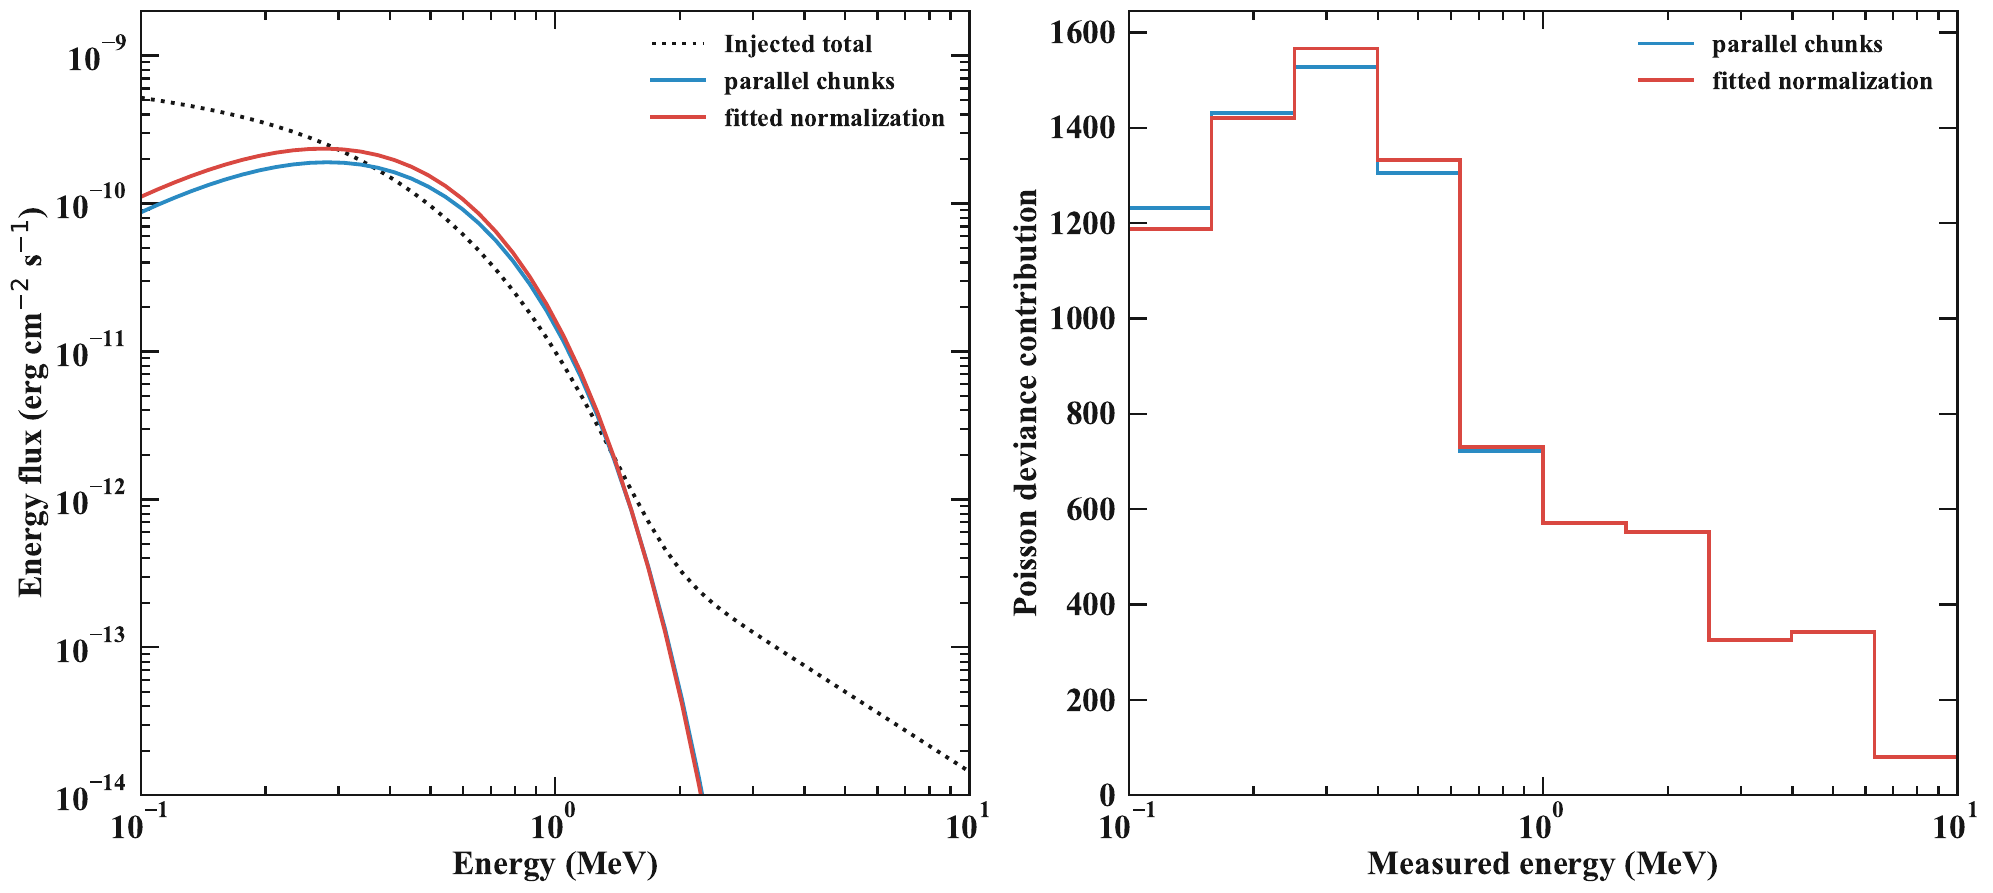

In [18]:
from agn_paper_plot_style import BLUE, ink, paper_style, style_axis
RED = "#D94841"
KEV_TO_ERG = u.keV.to(u.erg)
with paper_style("light", 22):
    fig, (ax_flux, ax_counts) = plt.subplots(1, 2, figsize=(18, 8), constrained_layout=True)
    for ax in (ax_flux, ax_counts):
        style_axis(ax, "light", 22)
    ax_flux.plot(energy/1000., KEV_TO_ERG*energy**2*original_injected_flux(energy),
                 color=ink("light"), ls=":", lw=2.5, label="Injected total")
    for result, color in ((parallel_best, BLUE), (fitnorm_best, RED)):
        ax_flux.plot(energy/1000., KEV_TO_ERG*energy**2*result["fit flux"],
                     color=color, lw=2.5, label=result["method"])
        ax_counts.stairs(result["energy deviance"], binned_energy_edges/1000.,
                         color=color, lw=2.3, label=result["method"])
    ax_flux.set(xscale="log", yscale="log", xlim=(0.1,10.),
                ylim=(1e-14, 2e-9), xlabel="Energy (MeV)",
                ylabel=r"Energy flux (erg cm$^{-2}$ s$^{-1}$)")
    ax_counts.set(xscale="log", xlim=(0.1,10.), ylim=(0, None),
                  xlabel="Measured energy (MeV)",
                  ylabel="Poisson deviance contribution")
    ax_flux.legend(frameon=False, fontsize=17)
    ax_counts.legend(frameon=False, fontsize=17)
    fig.savefig(output_dir / "NGC4151_DC4_fitnorm_vs_parallel_original_mock_white.pdf",
                facecolor="white", transparent=False, bbox_inches="tight")
    plt.show()
